<a href="https://colab.research.google.com/github/SitiMutmainah15/PEMBELAJARAN-MESIN_GENAP_2026/blob/main/JS08/TugasLab1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score

df = pd.read_csv("CC_Customer_Dataset.csv")

df.head()

,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3


In [2]:
X = df.drop(columns=["Sl_No", "Customer Key"])

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(X.columns)
print(X_scaled.shape)

Index(['Avg_Credit_Limit', 'Total_Credit_Cards', 'Total_visits_bank',
       'Total_visits_online', 'Total_calls_made'],
      dtype='object')
(660, 5)


In [3]:
model = AgglomerativeClustering(
    n_clusters=3,
    linkage="ward"
)

df["Cluster"] = model.fit_predict(X_scaled)

print(df["Cluster"].value_counts().sort_index())

Cluster
0    385
1    225
2     50
Name: count, dtype: int64


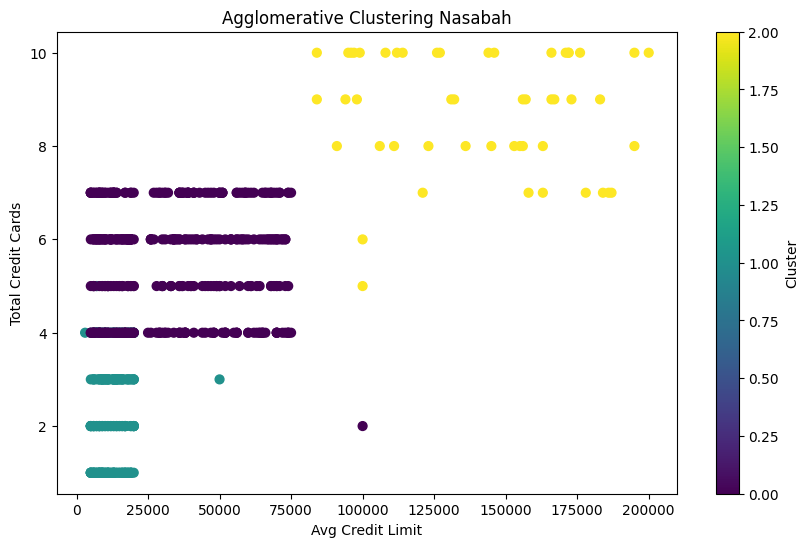

In [4]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df["Avg_Credit_Limit"],
    df["Total_Credit_Cards"],
    c=df["Cluster"],
    cmap="viridis",
    s=40
)

plt.xlabel("Avg Credit Limit")
plt.ylabel("Total Credit Cards")
plt.title("Agglomerative Clustering Nasabah")
plt.colorbar(label="Cluster")
plt.show()

In [5]:
sil_score = silhouette_score(X_scaled, df["Cluster"])
dbi_score = davies_bouldin_score(X_scaled, df["Cluster"])

print("Silhouette Score:", round(sil_score, 4))
print("Davies-Bouldin Index:", round(dbi_score, 4))

Silhouette Score: 0.5148
Davies-Bouldin Index: 0.681


In [6]:
hasil = df.groupby("Cluster")[X.columns].mean().round(2)
print(hasil)

         Avg_Credit_Limit  Total_Credit_Cards  Total_visits_bank  \
Cluster                                                            
0                33851.95                5.52               3.49   
1                12151.11                2.42               0.94   
2               141040.00                8.74               0.60   

         Total_visits_online  Total_calls_made  
Cluster                                         
0                       0.98              1.99  
1                       3.55              6.86  
2                      10.90              1.08  


Sesuai dengan hasil pengujian menggunakan metode yang diminta, didaptkan 3 cluster dari 660 data. Custer 0 385 nasabah, cluster 1 255 nasabah, cluster 2 50 nasabah. Hasil memperlihatkan nilai Silhoutte 0.5146 dan Davies 0,681. Ini menunjukan jika model bisa membentuk kelompok nasabah dengan pemisahan yang baik berdasarkan karakteristik penggunaan kartu kredit dan aktivitas bank.